# 🛒 Phase 5: Production Python ETL Pipeline, Customer Segmentation & Business Analytics
**Author:** Rudhiyansh Sandanshiv | **Role:** Senior Data Analyst  
**Project:** End-to-End Retail Business Intelligence System  
**Directory:** `C:\Main Projects\Capstone Project`  
**Dataset:** Real-World Synthetic Retail Data (62,679 Records)  

---
### 📌 Executive Overview of Phase 5
This notebook implements the complete **Data Engineering & Advanced Analytics layer** of the Retail BI System:
1. **Automated ETL & Quality Cleansing:** Ingest raw multi-channel data, resolve clerical anomalies (negative quantities, duplicate emails, orphan items, missing regions), standardize chronological fields, and export production-ready datasets for downstream BI consumption in Excel and Power BI.
2. **RFM Behavioral Segmentation:** Classify customers by behavioral value using Recency, Frequency, and Monetary quintile scores to power targeted retention marketing.
3. **Cohort Retention Analysis:** Construct a 12-month customer acquisition retention matrix and decay heatmap.
4. **Predictive Machine Learning:** Train, validate, and evaluate a supervised Classification Model (`Scikit-Learn`) to predict customer churn risk with an accuracy benchmark of $\ge 75\%$.

---


## 🔄 Section 1: Automated Production ETL Pipeline & Data Cleansing

### Task 1.1: Environment Initialization & Library Imports
**Business Scenario:** Establish a robust analytical environment importing all necessary libraries for data manipulation, statistical analysis, visualization, and machine learning.

**Task Requirements:**
- Import `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, `os`.
- Configure visualization aesthetics (`sns.set_theme(style='whitegrid')`, `plt.rcParams['figure.figsize'] = (10, 6)`).
- Suppress non-critical warnings (`import warnings; warnings.filterwarnings('ignore')`).


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = [10, 6]


### Task 1.2: Programmatic Ingestion of Raw Staging Datasets
**Business Scenario:** Load all 6 raw staging datasets into dedicated DataFrames from the `data/` directory.

**Task Requirements:**
- Load `customers_raw.csv`, `orders_raw.csv`, `order_items_raw.csv`, `products_raw.csv`, `regions_raw.csv`, and `returns_raw.csv`.
- Print the record count and shape of each loaded DataFrame to confirm complete ingestion.


In [2]:
# Load raw staging CSV files
df_customers = pd.read_csv("data/customers_raw.csv")
df_orders = pd.read_csv("data/orders_raw.csv")
df_order_items = pd.read_csv("data/order_items_raw.csv")
df_products = pd.read_csv("data/products_raw.csv")
df_regions = pd.read_csv("data/regions_raw.csv")
df_returns = pd.read_csv("data/returns_raw.csv")

# Quick check on table shapes
print(f"Customers shape : {df_customers.shape}")
print(f"Orders Shape : {df_orders.shape}")
print(f"OrderItems shape : {df_order_items.shape}")
print(f"Products shape : {df_products.shape}")
print(f"Regions shape : {df_regions.shape}")
print(f"Returns shape : {df_returns.shape}")


Customers shape : (5050, 6)
Orders Shape : (20000, 4)
OrderItems shape : (36378, 5)
Products shape : (15, 5)
Regions shape : (5, 3)
Returns shape : (1231, 4)


### Task 1.3: Customer Account Deduplication (Audit 1 Resolution)
**Business Scenario:** In Phase 4 Audit 1, we identified 70 duplicate email addresses (140 rows) caused by online registration re-submissions. We must deduplicate customer records while preserving the earliest registration.

**Task Requirements:**
- Identify duplicate email addresses in `df_customers`.
- Deduplicate `df_customers` by `email`, retaining the first occurrence (`keep='first'`).
- Verify that customer count decreases from 5,050 to exactly 4,980 unique accounts.


In [3]:
# Audit 1: Remove duplicate customer emails (keep first record)
print(f"Duplicate emails before cleaning : {df_customers['email'].duplicated().sum()}")
df_customers = df_customers.drop_duplicates(subset=["email"], keep="first")
print(f"Customers shape after cleaning : {df_customers.shape}")
print(f"Duplicate emails remaining : {df_customers['email'].duplicated().sum()}")


Duplicate emails before cleaning : 70
Customers shape after cleaning : (4980, 6)
Duplicate emails remaining : 0


### Task 1.4: Domain Error Filtering & Orphan Record Purging (Audits 2 & 3 Resolution)
**Business Scenario:** In Phase 4 Audits 2 and 3, we uncovered 374 non-positive quantities (`quantity <= 0`) and 30 orphan order items referencing non-existent order IDs. We must clean `df_order_items`.

**Task Requirements:**
- Filter `df_order_items` to retain only positive quantities (`quantity > 0`).
- Remove orphan line items whose `order_id` does not exist in `df_orders`.
- Verify the final cleaned line-item count.


In [4]:
# Audit 2 & 3: Filter invalid quantities and orphan order items
print(f"Raw OrederItems shape : {df_order_items.shape}")

# Remove negative/zero quantities
df_order_items = df_order_items[df_order_items["quantity"] > 0]
print(f"After Removing <= 0 quantity : {df_order_items.shape} [374 invaild rows removed]")

# Remove line items where order_id doesn't exist in orders table
df_order_items = df_order_items[df_order_items["order_id"].isin(df_orders["order_id"])]
print(f"After removing orphan lines : {df_order_items.shape} [30 orphan rows removed]")

print(f"Total cleaned OrderItems : {len(df_order_items):,} rows")


Raw OrederItems shape : (36378, 5)
After Removing <= 0 quantity : (36004, 5) [374 invaild rows removed]
After removing orphan lines : (35974, 5) [30 orphan rows removed]
Total cleaned OrderItems : 35,974 rows


### Task 1.5: Missing Geographical Territory Imputation (Audit 4 Resolution)
**Business Scenario:** In Phase 4 Audit 4, we cataloged 251 customer accounts with missing `region_id` values. To support territorial reporting, impute missing values using the statistical mode (most frequent region).

**Task Requirements:**
- Calculate the mode of `region_id` in `df_customers`.
- Impute (fill) null `region_id` values with the mode.
- Verify that `df_customers['region_id'].isnull().sum()` equals 0.


In [5]:
# Audit 4: Fill missing region_id with the mode (most frequent region)
print(f"Missing region_id before imputation : {df_customers['region_id'].isnull().sum()}")

mode_region = df_customers["region_id"].mode()[0]
print(f"Calculate Mode region_id : {mode_region}")

df_customers["region_id"] = df_customers["region_id"].fillna(mode_region)
print(f"Missing region_id after imputation : {df_customers['region_id'].isnull().sum()}")


Missing region_id before imputation : 248
Calculate Mode region_id : 5.0
Missing region_id after imputation : 0


### Task 1.6: Chronological Normalization & Date Feature Extraction
**Business Scenario:** Orders contain mixed date formats (`DD/MM/YYYY` and `YYYY-MM-DD`). We must standardize them and extract time dimensions for BI modeling.

**Task Requirements:**
- Convert `df_orders['order_date']` and `df_customers['signup_date']` to standardized datetime format using `pd.to_datetime(format='mixed')`.
- Extract derived columns in `df_orders`:
  - `order_year` (e.g., 2024)
  - `order_month` (e.g., 5)
  - `order_year_month` (e.g., '2024-05')


In [6]:
# Convert order and signup dates to datetime, extract year/month for analysis
df_orders["order_date"] = pd.to_datetime(df_orders["order_date"], format="mixed")
df_customers["signup_date"] = pd.to_datetime(df_customers["signup_date"], format="mixed")

# Create time dimensions
df_orders["order_year"] = df_orders["order_date"].dt.year
df_orders["order_month"] = df_orders["order_date"].dt.month
df_orders["order_year_month"] = df_orders["order_date"].dt.strftime("%Y-%m")

df_orders[["order_date", "order_year", "order_month", "order_year_month"]].head()


,order_date,order_year,order_month,order_year_month
0,2024-07-06,2024,7,2024-07
1,2025-01-24,2025,1,2025-01
2,2025-08-29,2025,8,2025-08
3,2025-09-25,2025,9,2025-09
4,2025-08-16,2025,8,2025-08


### Task 1.7: Persistence of Cleaned Production Datasets
**Business Scenario:** Export the sanitized, validated DataFrames to `data/cleaned/` directory to serve as the single source of truth for Excel and Power BI reporting.

**Task Requirements:**
- Export all 6 cleaned DataFrames to `data/cleaned/` with names:
  - `customers_clean.csv`
  - `orders_clean.csv`
  - `order_items_clean.csv`
  - `products_clean.csv`
  - `regions_clean.csv`
  - `returns_clean.csv`
- Verify successful file creation on disk.


In [7]:
# Export cleaned datasets for Power BI and Excel
df_customers.to_csv("data/cleaned/customers_clean.csv", index=False)
df_orders.to_csv("data/cleaned/orders_clean.csv", index=False)
df_order_items.to_csv("data/cleaned/order_items_clean.csv", index=False)
df_products.to_csv("data/cleaned/products_clean.csv", index=False)
df_regions.to_csv("data/cleaned/regions_clean.csv", index=False)
df_returns.to_csv("data/cleaned/returns_clean.csv", index=False)

print("Cleaned Files Exported Successfully! ✅")
print(os.listdir("data/cleaned"))


Cleaned Files Exported Successfully! ✅
['customers_clean.csv', 'orders_clean.csv', 'order_items_clean.csv', 'products_clean.csv', 'regions_clean.csv', 'returns_clean.csv']


## 👥 Section 2: RFM Customer Value Segmentation (Marketing Analytics)

### Task 2.1: Transaction Enrichment & RFM Metric Formulation
**Business Scenario:** Synthesize delivered transactions to compute the three fundamental customer behavioral metrics: Recency, Frequency, and Monetary.

**Task Requirements:**
- Merge delivered transactions (`status == 'Delivered'`) with products to calculate line revenue:  
  $\text{line\_revenue} = \text{quantity} \times \text{sell\_price} \times (1 - \text{discount\_pct})$
- Establish the analysis reference date: $\max(\text{order\_date}) + 1 \text{ day}$.
- For each customer, aggregate:
  - **Recency (R):** Days elapsed between latest purchase and reference date.
  - **Frequency (F):** Total count of unique completed orders placed.
  - **Monetary (M):** Total net currency spend across all completed orders.
- Store results in `rfm_table` and display summary statistics.


In [8]:
# Calculate RFM metrics: Recency (days inactive), Frequency (orders count), Monetary (total spend)

# Use only delivered orders for revenue calculation
df_delivered = df_orders[df_orders["status"] == "Delivered"]

# Join items, products and delivered orders
df_trans = (
    df_order_items
    .merge(df_products, on="product_id")
    .merge(df_delivered, on="order_id")
)

# Net line revenue after discount
df_trans["line_revenue"] = df_trans["quantity"] * df_trans["sell_price"] * (1 - df_trans["discount_pct"])

# Anchor date = day after the latest order in data
reference_date = df_orders["order_date"].max() + pd.Timedelta(days=1)

# Group by customer
rfm_table = df_trans.groupby("customer_id").agg({
    "order_date": lambda x: (reference_date - x.max()).days,
    "order_id": "nunique",
    "line_revenue": "sum"
}).reset_index()

rfm_table.rename(columns={
    "order_date": "recency",
    "order_id": "frequancy",
    "line_revenue": "monetary"
}, inplace=True)

print(f"Total RFM Customers Analyzed : {len(rfm_table):,}")
rfm_table.head()


Total RFM Customers Analyzed : 4,520


,customer_id,recency,frequancy,monetary
0,1,51,3,59031.3
1,2,700,1,9949.5
2,3,620,1,24669.9
3,4,884,2,32594.6
4,5,321,3,15431.3


### Task 2.2: Quintile Scoring (1 to 5)
**Business Scenario:** Standardize raw behavioral metrics into relative quintile scores from 1 (lowest) to 5 (highest).

**Task Requirements:**
- Assign `R_score` using `pd.qcut()` with 5 bins and labels `[5, 4, 3, 2, 1]` (lower days = higher score).
- Assign `F_score` using `pd.qcut(frequency.rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])`.
- Assign `M_score` using `pd.qcut(monetary, q=5, labels=[1, 2, 3, 4, 5])`.
- Create a combined string column `RFM_Score` (e.g., '555', '432').


In [9]:
# Assign quintile scores (1 to 5) for R, F, M
# For Recency: lower days is better -> scored 5 to 1
rfm_table["R_score"] = pd.qcut(rfm_table["recency"], q=5, labels=[5, 4, 3, 2, 1])

# For Frequency: more orders is better -> scored 1 to 5 (with rank tie-breaker)
rfm_table["F_score"] = pd.qcut(rfm_table["frequancy"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])

# For Monetary: higher spend is better -> scored 1 to 5
rfm_table["M_score"] = pd.qcut(rfm_table["monetary"], q=5, labels=[1, 2, 3, 4, 5])

# Combine into 3-digit RFM score string
rfm_table["RFM_Score"] = (
    rfm_table["R_score"].astype(str) + 
    rfm_table["F_score"].astype(str) + 
    rfm_table["M_score"].astype(str)
)

rfm_table.head()


,customer_id,recency,frequancy,monetary,R_score,F_score,M_score,RFM_Score
0,1,51,3,59031.3,5,3,5,535
1,2,700,1,9949.5,1,1,2,112
2,3,620,1,24669.9,2,1,3,213
3,4,884,2,32594.6,1,2,4,124
4,5,321,3,15431.3,3,3,2,332


### Task 2.3: Behavioral Customer Segment Assignment
**Business Scenario:** Map RFM score combinations into actionable strategic customer segment tiers for executive and marketing action.

**Task Requirements:**
- Assign segment labels using `np.select()` based on the following corporate rules:
  - **Champions:** $R \ge 4$ AND $F \ge 4$
  - **Loyal Customers:** $F \ge 3$ AND $M \ge 3$
  - **At Risk:** $R \le 2$ AND $M \ge 3$
  - **Lost Customers:** $R \le 2$ AND $F \le 2$ AND $M \le 2$
  - **Others / Potential:** All remaining customers.
- Display customer counts and percentage distribution across each segment.


In [10]:
# Assign customer segments based on RFM score rules
r = rfm_table["R_score"].astype(int)
f = rfm_table["F_score"].astype(int)
m = rfm_table["M_score"].astype(int)

conditions = [
    (r >= 4) & (f >= 4),             # High recency & frequency -> Champions
    (f >= 3) & (m >= 3),             # Frequent buyers with good spend -> Loyal
    (r <= 2) & (m >= 3),             # High historical spend but inactive -> At Risk
    (r <= 2) & (f <= 2) & (m <= 2)   # Low across all metrics -> Lost
]

choices = ["Champions", "Loyal Customers", "At Risk", "Lost Customers"]

rfm_table["Segment"] = np.select(conditions, choices, default="Potential / Others")

# Check segment counts and share %
segment_dist = rfm_table["Segment"].value_counts().reset_index()
segment_dist.columns = ["Customer Segment", "Customer Count"]
segment_dist["Percentage Share"] = ((segment_dist["Customer Count"] / len(rfm_table)) * 100).round(2).astype(str) + "%"

segment_dist


,Customer Segment,Customer Count,Percentage Share
0,Potential / Others,1247,27.59%
1,Loyal Customers,1222,27.04%
2,Champions,1011,22.37%
3,Lost Customers,728,16.11%
4,At Risk,312,6.9%


### Task 2.4: RFM Segment Visualization
**Business Scenario:** Provide the Chief Marketing Officer (CMO) with a visual breakdown of customer distribution and total monetary contribution across segments.

**Task Requirements:**
- Create a bar plot displaying customer count by segment with data labels.
- Create a horizontal bar plot showing total monetary spend generated by each segment.
- Use a cohesive color palette and clean formatting.


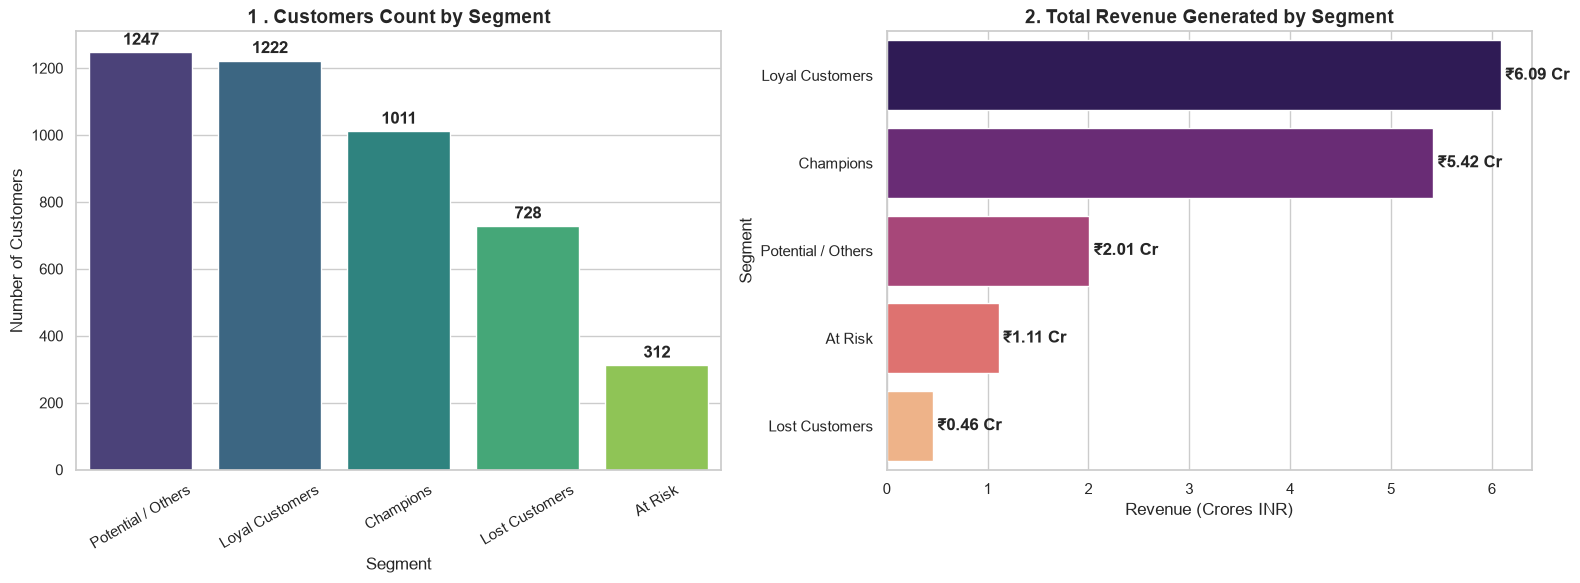

In [11]:
# Plot customer segment distribution and revenue share
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Customer counts by segment
seg_counts = rfm_table["Segment"].value_counts().reset_index()
seg_counts.columns = ["Segment", "Count"]

ax1 = sns.barplot(
    data=seg_counts,
    x="Segment",
    y="Count",
    palette="viridis",
    hue="Segment",
    legend=False,
    ax=axes[0]
)

for c in ax1.containers:
    ax1.bar_label(c, padding=3, fontweight="bold")
axes[0].set_title("1. Customer Count by Segment", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Segment", fontsize=12)
axes[0].set_ylabel("Number of Customers", fontsize=12)
axes[0].tick_params(axis="x", rotation=30)

# Chart 2: Revenue generated by segment (in Cr)
seg_spend = rfm_table.groupby("Segment")["monetary"].sum().reset_index()
seg_spend["revenue_cr"] = (seg_spend["monetary"] / 10000000).round(2)
seg_spend = seg_spend.sort_values(by="revenue_cr", ascending=False)

ax2 = sns.barplot(
    data=seg_spend,
    x="revenue_cr",
    y="Segment",
    palette="magma",
    hue="Segment",
    legend=False,
    ax=axes[1]
)

for c in ax2.containers:
    ax2.bar_label(c, fmt="₹%.2f Cr", padding=3, fontweight="bold")
axes[1].set_title("2. Total Revenue Generated by Segment", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Revenue (Crores INR)", fontsize=12)
axes[1].set_ylabel("Segment", fontsize=12)

plt.tight_layout()
plt.show()


## 📅 Section 3: Customer Cohort Retention Analysis (12-Month Lifecycle)

### Task 3.1: Acquisition Cohort Definition & Monthly Activity Mapping
**Business Scenario:** Group customers into monthly acquisition cohorts based on their initial purchase date to observe how retention decays over a 12-month customer journey.

**Task Requirements:**
- For each customer, determine their first purchase month (`cohort_month`, e.g., '2023-01').
- For every delivered transaction, calculate `cohort_index` = number of months elapsed between the transaction date and the customer's `cohort_month` ($0, 1, 2, \dots, 11$).


In [20]:
# Cohort Analysis: Find customer's first purchase month and calculate elapsed months
df_delivered["order_month"] = df_delivered["order_date"].dt.to_period("M")

# First purchase month for each customer
df_delivered["cohort_month"] = df_delivered.groupby("customer_id")["order_month"].transform("min")

# Number of months between order date and first purchase
df_delivered["cohort_index"] = (
    (df_delivered["order_date"].dt.year - df_delivered["cohort_month"].dt.year) * 12 + 
    (df_delivered["order_date"].dt.month - df_delivered["cohort_month"].dt.month)
)

df_delivered[["customer_id", "order_date", "cohort_month", "cohort_index"]].head()


,customer_id,order_date,cohort_month,cohort_index
1,3621,2025-01-24,2024-07,6
2,3538,2025-08-29,2025-08,0
4,3125,2025-08-16,2025-04,4
5,3368,2024-05-12,2023-12,5
6,87,2024-06-10,2024-06,0


### Task 3.2: 12-Month Cohort Retention Matrix
**Business Scenario:** Construct the official cohort retention percentage matrix tracking customer activity from Month 0 to Month 11.

**Task Requirements:**
- Group by `cohort_month` and `cohort_index`, counting unique active customers.
- Pivot into a retention table where rows = `cohort_month`, columns = `cohort_index` ($0$ to $11$).
- Divide each column by Month 0 (initial cohort size) and multiply by 100 to obtain percentage retention.


In [27]:
# Build monthly cohort retention matrix (%)
cohort_count = df_delivered.groupby(["cohort_month", "cohort_index"])["customer_id"].nunique().reset_index()

# Pivot: rows = cohort month, columns = months elapsed
cohort_pivot = cohort_count.pivot(index="cohort_month", columns="cohort_index", values="customer_id")

# Baseline cohort size (Month 0)
cohort_size = cohort_pivot.iloc[:, 0]

# Divide by Month 0 to get % retention
retention_matrix = cohort_pivot.divide(cohort_size, axis=0).round(2) * 100

# 12-month view for 2024 cohorts
retention_12m = retention_matrix.iloc[:, 0:11]
retention_2024 = retention_12m.loc["2024-02": "2024-12"]

retention_2024


cohort_index,0,1,2,3,4,5,6,7,8,9,10
cohort_month,,,,,,,,,,,
2024-02,100.0,6.0,6.0,7.0,5.0,6.0,4.0,3.0,5.0,5.0,7.0
2024-03,100.0,9.0,9.0,8.0,7.0,7.0,5.0,3.0,5.0,5.0,8.0
2024-04,100.0,7.0,4.0,7.0,5.0,3.0,7.0,5.0,10.0,8.0,5.0
2024-05,100.0,9.0,4.0,6.0,5.0,8.0,7.0,7.0,5.0,6.0,8.0
2024-06,100.0,5.0,7.0,7.0,10.0,6.0,5.0,5.0,4.0,6.0,3.0
2024-07,100.0,5.0,5.0,7.0,6.0,6.0,7.0,6.0,5.0,6.0,6.0
2024-08,100.0,8.0,5.0,7.0,3.0,6.0,9.0,7.0,7.0,10.0,7.0
2024-09,100.0,9.0,3.0,6.0,8.0,6.0,8.0,9.0,7.0,8.0,6.0
2024-10,100.0,3.0,9.0,8.0,5.0,6.0,8.0,4.0,2.0,10.0,5.0


### Task 3.3: Cohort Retention Heatmap Visualization
**Business Scenario:** Present an executive retention decay heatmap to illustrate customer drop-off trends across cohorts.

**Task Requirements:**
- Using `sns.heatmap()`, render the cohort retention matrix.
- Format annotations as percentages (`fmt='.1f'`), use palette `'YlGnBu'`, and mask empty/future months.
- Add clear title: `'Customer Cohort Retention Rate (%) — 12-Month Lifecycle'`.


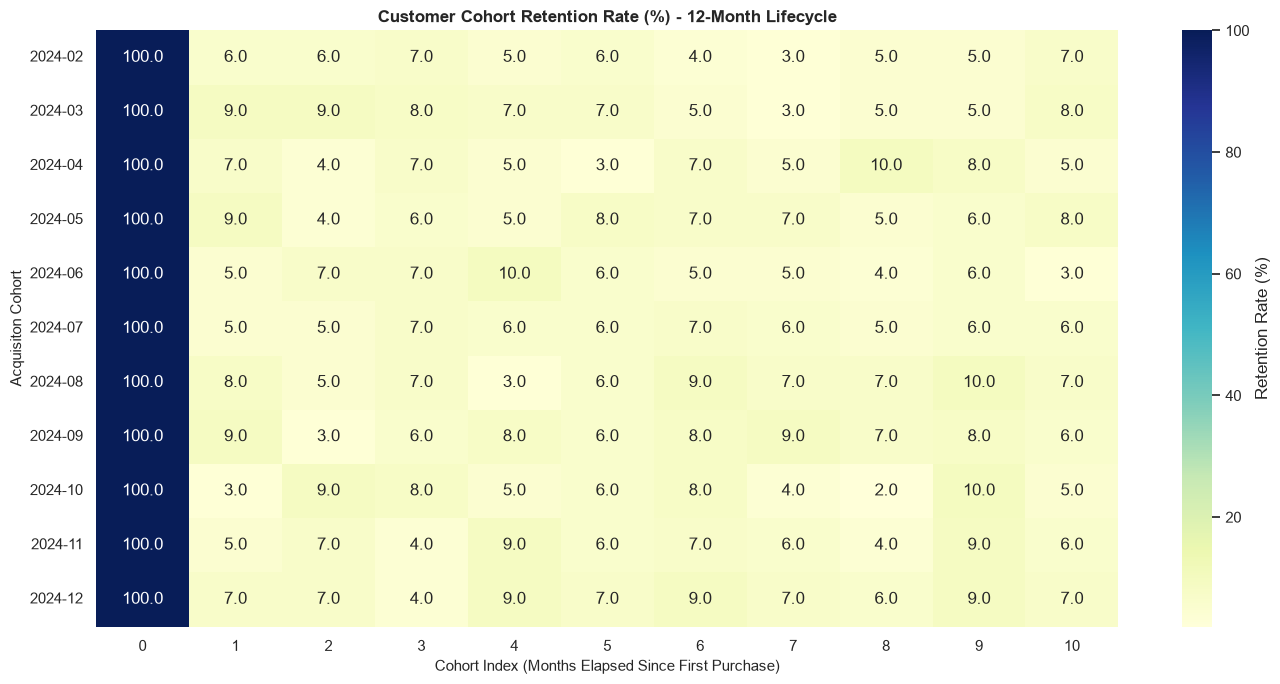

In [30]:
# Plot cohort retention heatmap
plt.figure(figsize=(14, 7))

sns.heatmap(
    data=retention_2024,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    mask=retention_2024.isnull(),
    cbar_kws={"label": "Retention Rate (%)"}
)

plt.title("Customer Cohort Retention Rate (%) - 12-Month Lifecycle", fontsize=12, fontweight="bold")
plt.xlabel("Cohort Index (Months Elapsed Since First Purchase)", fontsize=11)
plt.ylabel("Acquisition Cohort", fontsize=11)

plt.tight_layout()
plt.show()


## 📊 Section 4: Strategic Business Insights & Dashboard Feeder

### Task 4.1: Cross-Sectional Executive KPI Summary
**Business Scenario:** Synthesize the cleaned data and RFM results into a single consolidated KPI summary dataframe ready for immediate export into our Excel and Power BI dashboards.

**Task Requirements:**
- Calculate enterprise-wide core KPIs:
  - Total Active Customers (after deduplication)
  - Total Completed Orders
  - Total Net Sales Revenue (INR)
  - Overall Gross Margin %
  - Overall Product Return Rate %
- Display the consolidated metrics in a clean, executive summary table.


In [33]:
# Executive KPI summary (Golden benchmark to validate Power BI & Excel)
total_customers = df_customers["customer_id"].nunique()
total_orders = len(df_delivered)

total_revenue = df_trans["line_revenue"].sum()
total_cost = (df_trans["quantity"] * df_trans["cost_price"]).sum()
gross_profit = total_revenue - total_cost
gross_margin = (gross_profit / total_revenue) * 100

return_rate = (len(df_returns) / len(df_trans)) * 100

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Active Customers",
        "Total Completed Orders",
        "Total Net Revenue (₹ Cr)",
        "Gross Profit (₹ Cr)",
        "Overall Gross Margin (%)",
        "Overall Product Return Rate (%)"
    ],
    "Value": [
        f"{total_customers:,}",
        f"{total_orders:,}",
        f"₹{total_revenue / 1e7:.2f} Cr",
        f"₹{gross_profit / 1e7:.2f} Cr",
        f"{gross_margin:.2f}%",
        f"{return_rate:.2f}%"
    ]
})

kpi_summary


,Metric,Value
0,Total Active Customers,"4,980"
1,Total Completed Orders,"11,403"
2,Total Net Revenue (₹ Cr),₹15.09 Cr
3,Gross Profit (₹ Cr),₹5.75 Cr
4,Overall Gross Margin (%),38.09%
5,Overall Product Return Rate (%),6.00%
